In [34]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from skopt import BayesSearchCV
from xgboost import XGBRegressor
from xgboost import plot_importance


In [35]:
def lease_to_years(value):
    if pd.isna(value):
        return np.nan
    
    years = re.search(r"(\d+)\s*years?", str(value))
    months = re.search(r"(\d+)\s*months?", str(value))
    return (int(years.group(1)) if years else 0) + (int(months.group(1)) / 12 if months else 0)

In [36]:
num_cols = ['floor_area_sqm', 'lease_commence_date', 'sale_year', 'sale_month', 'remaining_lease_years']
cat_cols = ['town', 'flat_type', 'street_name', 'storey_range', 'flat_model']

num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
])

cat_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ('encoder',OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('cat', cat_pipeline, cat_cols),
    ('num', num_pipeline, num_cols)
])

df = pd.read_csv("/Users/amel/Projects/HDBPredictor/data.csv")
df["sale_date"] = pd.to_datetime(df["month"], format="%Y-%m")

df["remaining_lease_years"] = df["remaining_lease"].apply(lease_to_years)

df["sale_year"] = df["sale_date"].dt.year
df["sale_month"] = df["sale_date"].dt.month

X = df.drop(columns=["resale_price", "block", "month", "sale_date", "remaining_lease"])
y = df["resale_price"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

param_space = {
    "model__learning_rate": (0.01, 0.3, "log-uniform"),
    "model__max_depth": (3, 10),
    "model__n_estimators": (200, 1200),
    "model__min_child_weight": (1, 10),
    "model__subsample": (0.6, 1.0, "uniform"),
    "model__colsample_bytree": (0.6, 1.0, "uniform"),
    "model__reg_alpha": (1e-3, 10.0, "log-uniform"),
    "model__reg_lambda": (0.1, 20.0, "log-uniform"),
}

model = BayesSearchCV(
 estimator=XGBRegressor(n_jobs=1),
 search_spaces=param_space,
 scoring='neg_mean_squared_error',
 cv=3,
 n_iter=50,
)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', model)
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print(f"MAE: ${mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: ${root_mean_squared_error(y_test, y_pred):.2f}")
print(f"R^2: {r2_score(y_test, y_pred):.3f}")

/Users/amel/Projects/HDBPredictor/.venv/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [21:22:23] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "model__colsample_bytree", "model__learning_rate", "model__max_depth", "model__min_child_weight", "model__n_estimators", "model__reg_alpha", "model__reg_lambda", "model__subsample" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Users/amel/Projects/HDBPredictor/.venv/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [21:22:24] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "model__colsample_bytree", "model__learning_rate", "model__max_depth", "model__min_child_weight", "model__n_estimators", "model__reg_alpha", "model__reg_lambda", "model__subsample" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Users/amel/Projects/HDBPredictor/.venv/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [21:22:24] WARN

MAE: $27772.66
RMSE: $37808.81
R^2: 0.962


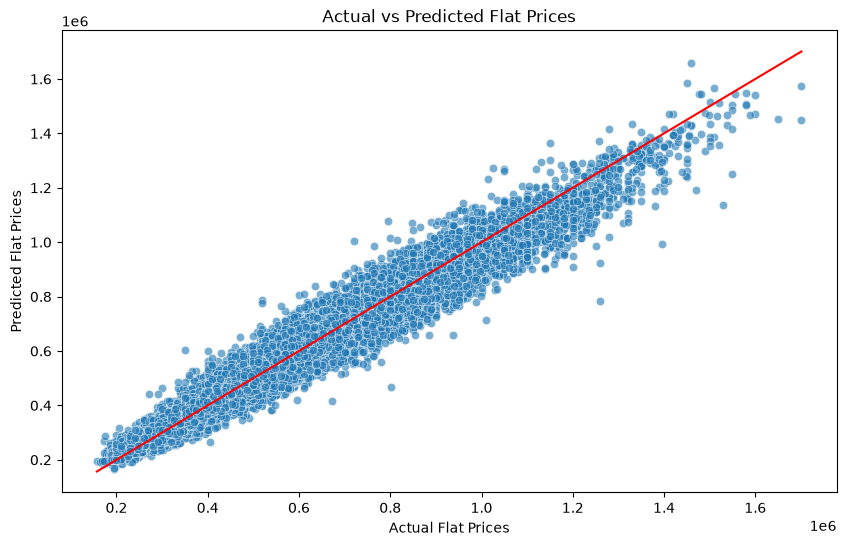

OrderedDict({'model__colsample_bytree': 0.976431816127648, 'model__learning_rate': 0.15950806210599686, 'model__max_depth': 7, 'model__min_child_weight': 7, 'model__n_estimators': 1073, 'model__reg_alpha': 0.6914735247267029, 'model__reg_lambda': 0.39202225983229017, 'model__subsample': 0.8962823224168459})


In [43]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted Flat Prices')
plt.xlabel('Actual Flat Prices')
plt.ylabel('Predicted Flat Prices')
plt.show()
print(model.best_params_)

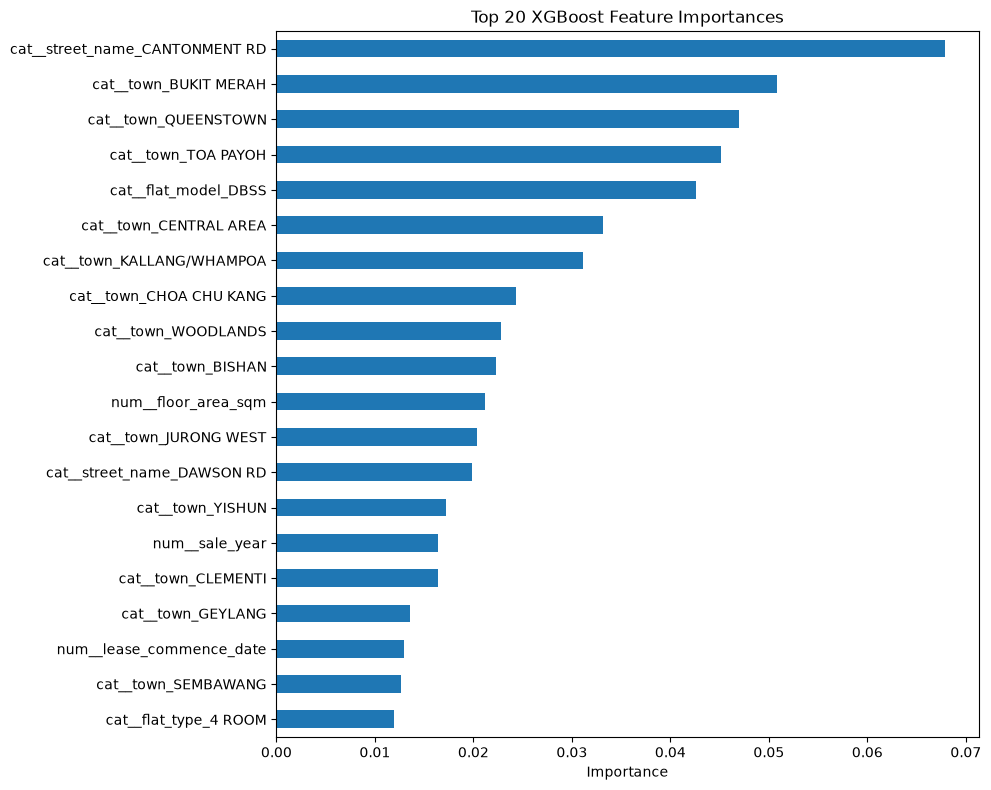

In [ ]:

feature_names = preprocessor.get_feature_names_out()

importance = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

importance.head(20).sort_values().plot(
    kind="barh", figsize=(10, 8)
)
plt.title("Top 20 XGBoost Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

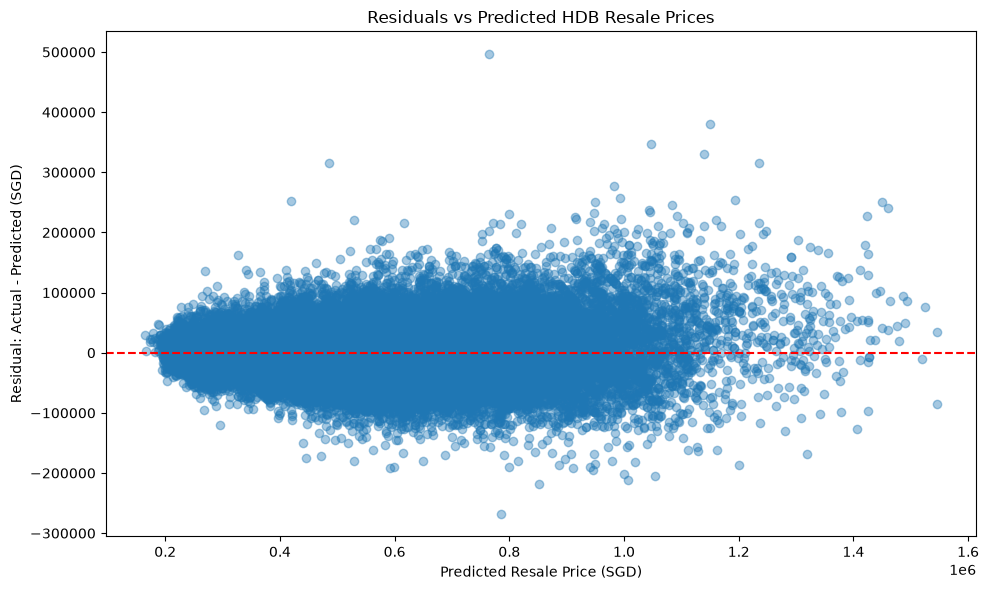

In [ ]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Resale Price (SGD)")
plt.ylabel("Residual: Actual - Predicted (SGD)")
plt.title("Residuals vs Predicted HDB Resale Prices")
plt.tight_layout()
plt.show()

In [ ]:

errors = pd.DataFrame({
    "actual": np.asarray(y_test),
    "predicted": y_pred,
    "error": np.asarray(y_test) - y_pred
})

errors["absolute_error"] = errors["error"].abs()

print(
    errors.sort_values("absolute_error", ascending=False)
          .head(10)
          .round(0)
)

          actual  predicted     error  absolute_error
14336  1260000.0   763782.0  496218.0        496218.0
43117  1530000.0  1149089.0  380911.0        380911.0
32366  1395000.0  1047596.0  347404.0        347404.0
8941   1470000.0  1139549.0  330451.0        330451.0
43826  1550000.0  1235071.0  314929.0        314929.0
38110   800888.0   486020.0  314868.0        314868.0
5163   1260000.0   982345.0  277655.0        277655.0
30366   518000.0   785350.0 -267350.0        267350.0
39027  1250000.0   992952.0  257048.0        257048.0
52102  1448000.0  1194015.0  253985.0        253985.0
